**Transformasi Fourier dan Pemrosesan Citra dalam Domain Frekuensi**

---

### 1. Konsep Transformasi Fourier

Transformasi Fourier digunakan untuk menganalisis komponen frekuensi dalam suatu sinyal atau citra. Dalam konteks pengolahan citra digital, Fourier Transform mengubah citra dari domain spasial ke domain frekuensi.

- **Fungsi**: Mengidentifikasi komponen frekuensi tinggi (detail, noise) dan frekuensi rendah (struktur global).
- **Transformasi Fourier 2D**: Menghasilkan representasi citra berdasarkan magnitudo dan fase dari frekuensi.

---

### 2. DFT dan FFT

- **DFT (Discrete Fourier Transform)**:
  $$ F(u,v) = \sum_{x=0}^{M-1}\sum_{y=0}^{N-1} f(x,y) \cdot e^{-j2\pi(ux/M + vy/N)} $$
  Digunakan untuk mengubah citra dari domain spasial ke frekuensi. Proses ini kompleks dan membutuhkan komputasi tinggi.

- **FFT (Fast Fourier Transform)**:
  Algoritma cepat untuk menghitung DFT dengan kompleksitas lebih rendah (O(N log N)), sangat efisien secara komputasi dan umum digunakan dalam implementasi praktis.

---

### 3. Representasi Citra dalam Domain Frekuensi

- **Magnitude Spectrum**: Menunjukkan intensitas dari komponen frekuensi (terlihat pada spektrum log-magnitude).
- **Phase Spectrum**: Menyimpan informasi struktur spasial citra.
- **Shifted Spectrum**: Memusatkan frekuensi nol ke tengah (menggunakan `np.fft.fftshift`) untuk visualisasi yang lebih baik.

---

### 4. Implementasi Python (Jupyter Notebook)

#### a. Transformasi Fourier

```python
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load gambar grayscale
img = cv2.imread('Image.jpeg', cv2.IMREAD_GRAYSCALE)

# DFT dan geser frekuensi nol ke tengah
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)

# Hitung spektrum magnitudo (log scale agar terlihat jelas)
magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray')
plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Magnitude Spectrum'), plt.axis('off')
plt.show()
```

#### b. Inverse DFT (Kembali ke domain spasial)

```python
# Inverse FFT
f_ishift = np.fft.ifftshift(fshift)
img_back = np.fft.ifft2(f_ishift)
img_back = np.abs(img_back)

plt.imshow(img_back, cmap='gray')
plt.title("Citra Rekonstruksi (Inverse FFT)")
plt.axis('off')
plt.show()
```

---

### 5. Diagram Pemrosesan dalam Domain Frekuensi

```
Input Citra
    ↓
DFT / FFT
    ↓
Operasi Filter (LPF / HPF)
    ↓
Inverse DFT / IFFT
    ↓
Output Citra (Enhanced)
```

---

### 6. Kesimpulan

- Transformasi Fourier mengungkap struktur frekuensi citra.
- FFT digunakan karena efisiensi tinggi dalam menghitung DFT.
- Representasi dalam domain frekuensi memudahkan pemrosesan seperti smoothing dan sharpening menggunakan filter frekuensi.
- Kombinasi magnitude dan phase spectrum penting untuk menjaga kualitas rekonstruksi citra.

Eksperimen dan visualisasi spektrum frekuensi sangat membantu dalam memahami distribusi frekuensi pada citra dan efek transformasi tersebut.



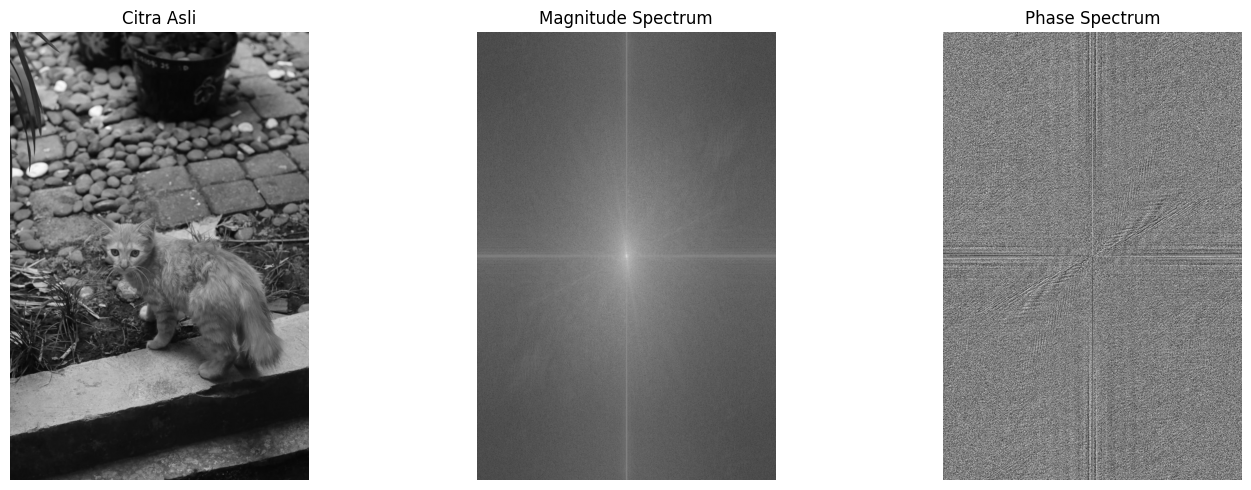

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load gambar grayscale
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

# DFT dan geser frekuensi nol ke tengah
# DFT dan geser frekuensi nol ke tengah
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)

# Hitung spektrum magnitudo dan spektrum fase
magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1)
phase_spectrum = np.angle(fshift)  # <<< PHASE SPECTRUM

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Magnitude Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(phase_spectrum, cmap='gray')
plt.title('Phase Spectrum')
plt.axis('off')

plt.tight_layout()
plt.show()


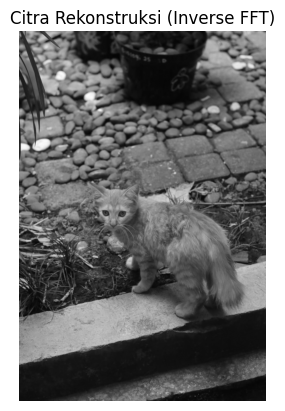

In [2]:
f_ishift = np.fft.ifftshift(fshift)
img_back = np.fft.ifft2(f_ishift)
img_back = np.abs(img_back)

plt.imshow(img_back, cmap='gray')
plt.title("Citra Rekonstruksi (Inverse FFT)")
plt.axis('off')
plt.show()

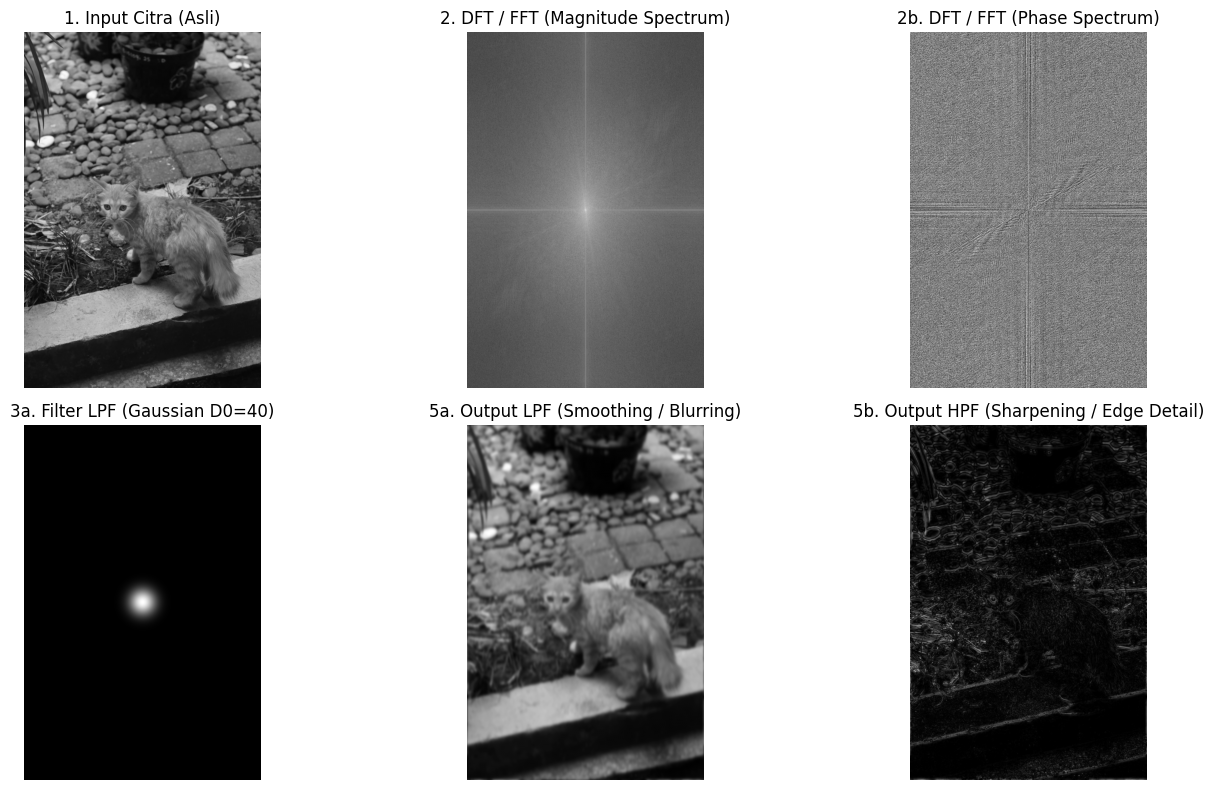

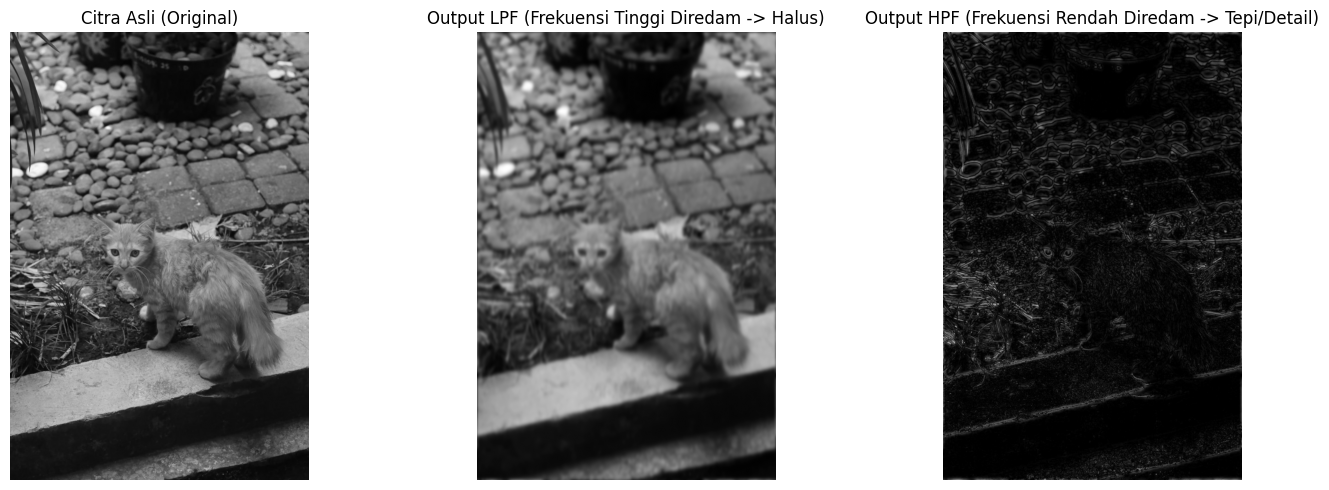

In [9]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_path = 'image.jpg' if os.path.exists('image.jpg') else ('Image.jpeg' if os.path.exists('Image.jpeg') else 'img.png')
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Citra '{img_path}' tidak ditemukan!")

F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)

M, N = img.shape
u = np.arange(M)
v = np.arange(N)
U, V = np.meshgrid(v, u)
D = np.sqrt((U - N // 2) ** 2 + (V - M // 2) ** 2)

D0 = 40
H_lpf = np.exp(-(D ** 2) / (2 * (D0 ** 2)))
H_hpf = 1.0 - H_lpf                       

G_lpf_shift = F_shift * H_lpf
G_hpf_shift = F_shift * H_hpf

G_lpf = np.fft.ifftshift(G_lpf_shift)
img_lpf = np.abs(np.fft.ifft2(G_lpf))
img_lpf = np.clip(img_lpf, 0, 255).astype(np.uint8)

G_hpf = np.fft.ifftshift(G_hpf_shift)
img_hpf = np.abs(np.fft.ifft2(G_hpf))
img_hpf = np.clip(img_hpf, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('1. Input Citra (Asli)')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(20 * np.log(np.abs(F_shift) + 1), cmap='gray')
plt.title('2. DFT / FFT (Magnitude Spectrum)')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(phase_spectrum, cmap='gray')
plt.title('2b. DFT / FFT (Phase Spectrum)')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(H_lpf, cmap='gray')
plt.title(f'3a. Filter LPF (Gaussian D0={D0})')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(img_lpf, cmap='gray')
plt.title('5a. Output LPF (Smoothing / Blurring)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(img_hpf, cmap='gray')
plt.title('5b. Output HPF (Sharpening / Edge Detail)')
plt.axis('off')

plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli (Original)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_lpf, cmap='gray')
plt.title('Output LPF (Frekuensi Tinggi Diredam -> Halus)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_hpf, cmap='gray')
plt.title('Output HPF (Frekuensi Rendah Diredam -> Tepi/Detail)')
plt.axis('off')

plt.tight_layout()
plt.show()